In [33]:
import numpy as np
import struct
import matplotlib.pyplot as plt

In [34]:
with open('prof.bin', 'rb') as f:
    data = f.read()
threads, = struct.unpack('q', data[:8])
data = np.frombuffer(data[8:], dtype=np.uint64).reshape(threads, -1, 6)

In [35]:
cost = np.diff(data, axis=-1)
cost.shape

(2, 500000, 5)

In [36]:
avg_cost = cost.mean(axis=1)

In [37]:
names = [
    '1. barrier',
    '2. pull',
    '3. step',
    '4. barrier',
    '5. push',
]

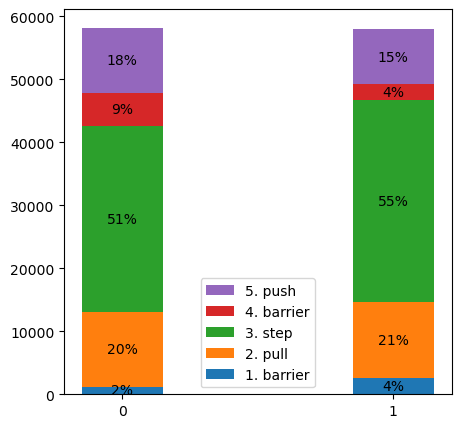

In [38]:
x = np.arange(cost.shape[0])
items = []
plt.figure(figsize=(5,5))
total_cost = np.sum(avg_cost, axis=-1)
for i in range(5):
    bottom = np.sum(avg_cost[:, :i], axis=-1)
    item = plt.bar(x, avg_cost[:, i], bottom=bottom, width=0.3)
    for j in range(cost.shape[0]):
        pct = avg_cost[j, i] / total_cost[j]
        plt.text(x[j], bottom[j] + avg_cost[j, i] / 2, f'{pct:.0%}', ha='center', va='center')
    items.append(item)
plt.legend(items[::-1], names[::-1])
plt.xticks(x, x)
plt.show()

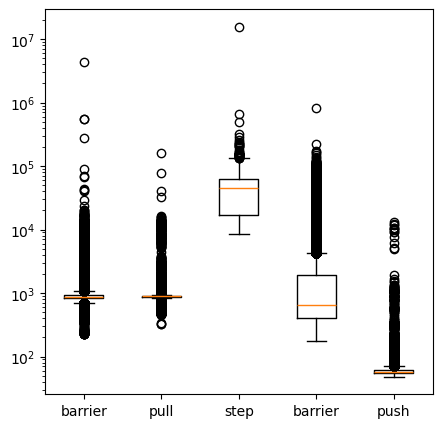

In [25]:
plt.figure(figsize=(5,5))
plt.boxplot(cost[0, :], tick_labels=['barrier', 'pull', 'step', 'barrier', 'push'])
plt.yscale('log')

<BarContainer object of 3 artists>

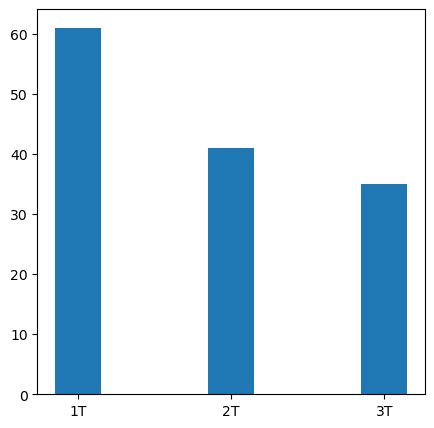

In [26]:
perf = [61, 41, 35, ]
plt.figure(figsize=(5,5))
plt.bar(['1T', '2T', '3T'], perf, width=0.3)